# FIGNN validation notebook

This notebook evaluates the full-population checkpoint, LOSO outputs, and new ablation checkpoints. 

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")

BASE_DIR = Path("/lp-dev/24BCE1793/outputs/evaluation_loso_all29")

REPORT_PATH = BASE_DIR / "loso_all29_report.json"
SUBJECT_CSV = BASE_DIR / "loso_all29_subject_metrics.csv"

FIG_DIR = BASE_DIR / "validation_figures"
FIG_DIR.mkdir(exist_ok=True)

print("Base directory:", BASE_DIR)
print("Report exists:", REPORT_PATH.exists())
print("CSV exists:", SUBJECT_CSV.exists())

Base directory: /lp-dev/24BCE1793/outputs/evaluation_loso_all29
Report exists: True
CSV exists: True


In [4]:
assert report["n_subjects"] == 29
assert report["checkpoint_count"] == 29
assert len(df) == 29

assert df["subject"].nunique() == 29
assert df["checkpoint"].notna().all()

required_columns = [
    "subject",
    "d01_x",
    "d02_x",
    "d12_x",
    "monotonicity",
    "oneback_between_x",
    "oneback_between_y",
    "relative_1back_position",
    "perpendicular_distance",
    "angle_deg",
    "path_efficiency",
    "procrustes_similarity",
    "direction_cosine",
    "spearman_rho",
    "knn5_accuracy",
    "knn5_balanced_accuracy",
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("All required columns are present.")
print("No duplicate subjects:", not df["subject"].duplicated().any())

All required columns are present.
No duplicate subjects: True


In [5]:
n = len(df)

d01_condition = df["d01_x"] < df["d02_x"]
between_condition = df["oneback_between_x"].astype(bool)
between_y_condition = df["oneback_between_y"].astype(bool)

print("Primary trajectory results")
print("-" * 50)

print(f"d01 < d02:          {d01_condition.sum()} / {n}")
print(f"1-back between:     {between_condition.sum()} / {n}")
print(f"1-back between Y:   {between_y_condition.sum()} / {n}")

print()
print("Stored report counts")
print("-" * 50)

print("monotonic_d01_lt_d02:",
      report["counts"]["monotonic_d01_lt_d02"])

print("oneback_between:",
      report["counts"]["oneback_between"])

Primary trajectory results
--------------------------------------------------
d01 < d02:          28 / 29
1-back between:     25 / 29
1-back between Y:   25 / 29

Stored report counts
--------------------------------------------------
monotonic_d01_lt_d02: 28
oneback_between: 25


In [6]:
def proportion_summary(successes, total, label):
    ci_low, ci_high = proportion_confint(
        count=successes,
        nobs=total,
        alpha=0.05,
        method="beta"
    )

    proportion = successes / total

    return {
        "metric": label,
        "successes": successes,
        "total": total,
        "proportion": proportion,
        "percentage": 100 * proportion,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_low_percentage": 100 * ci_low,
        "ci_high_percentage": 100 * ci_high,
    }


trajectory_stats = pd.DataFrame([
    proportion_summary(
        int(d01_condition.sum()),
        n,
        "d01 < d02"
    ),
    proportion_summary(
        int(between_condition.sum()),
        n,
        "1-back between C0 and C2"
    ),
    proportion_summary(
        int(between_y_condition.sum()),
        n,
        "1-back between using Y geometry"
    ),
])

display(trajectory_stats)

,metric,successes,total,proportion,percentage,ci_low,ci_high,ci_low_percentage,ci_high_percentage
0,d01 < d02,28,29,0.965517,96.551724,0.822356,0.999127,82.235570,99.912735
1,1-back between C0 and C2,25,29,0.862069,86.206897,0.683359,0.961105,68.335939,96.110517
2,1-back between using Y geometry,25,29,0.862069,86.206897,0.683359,0.961105,68.335939,96.110517


In [7]:
binomial_results = []

for row in trajectory_stats.itertuples():
    result = stats.binomtest(
        k=row.successes,
        n=row.total,
        p=0.5,
        alternative="greater"
    )

    binomial_results.append({
        "metric": row.metric,
        "successes": row.successes,
        "total": row.total,
        "proportion": row.proportion,
        "p_value_vs_0.5": result.pvalue,
    })

binomial_df = pd.DataFrame(binomial_results)

display(binomial_df)

,metric,successes,total,proportion,p_value_vs_0.5
0,d01 < d02,28,29,0.965517,5.587935e-08
1,1-back between C0 and C2,25,29,0.862069,5.185790e-05
2,1-back between using Y geometry,25,29,0.862069,5.185790e-05


In [8]:
metric_columns = [
    "d01_x",
    "d02_x",
    "d12_x",
    "relative_1back_position",
    "perpendicular_distance",
    "path_efficiency",
    "angle_deg",
    "direction_cosine",
]

display(
    df[metric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
d01_x,29.0,0.019360,0.013292,0.003683,0.010298,0.016141,0.024200,0.063274
d02_x,29.0,0.039605,0.030338,0.006009,0.019710,0.031793,0.047203,0.120547
d12_x,29.0,0.030278,0.021838,0.008331,0.013642,0.021515,0.042111,0.091393
relative_1back_position,29.0,0.190688,0.627438,-2.824970,0.094182,0.300649,0.457733,0.908861
perpendicular_distance,29.0,0.010848,0.006300,0.003623,0.006466,0.010123,0.011708,0.027005
path_efficiency,29.0,0.772958,0.180769,0.133892,0.676426,0.778344,0.915336,0.976135
angle_deg,29.0,80.306066,36.889557,25.865969,48.477978,83.991180,102.302940,172.960831
direction_cosine,29.0,0.611681,0.421392,-0.878564,0.552375,0.721122,0.897339,0.973827


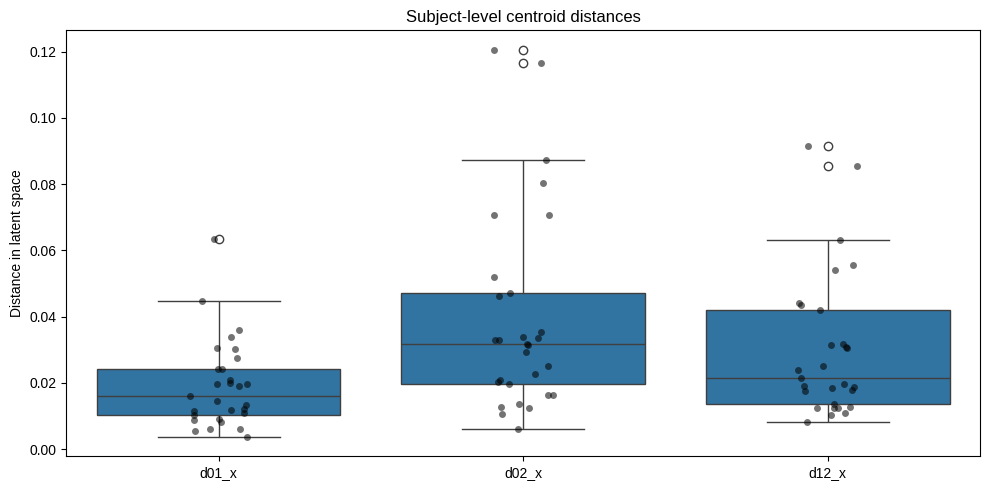

In [9]:
plt.figure(figsize=(10, 5))

distance_data = df[["subject", "d01_x", "d02_x", "d12_x"]].copy()
distance_long = distance_data.melt(
    id_vars="subject",
    var_name="metric",
    value_name="distance"
)

sns.boxplot(
    data=distance_long,
    x="metric",
    y="distance"
)

sns.stripplot(
    data=distance_long,
    x="metric",
    y="distance",
    color="black",
    alpha=0.55
)

plt.title("Subject-level centroid distances")
plt.xlabel("")
plt.ylabel("Distance in latent space")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "subject_centroid_distances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

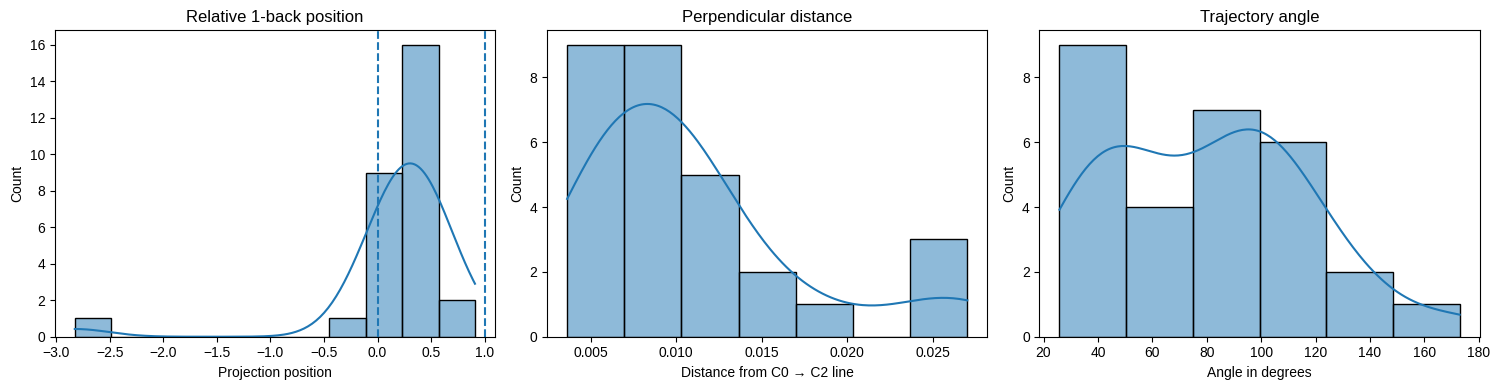

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    df["relative_1back_position"],
    kde=True,
    ax=axes[0]
)
axes[0].axvline(0, linestyle="--")
axes[0].axvline(1, linestyle="--")
axes[0].set_title("Relative 1-back position")
axes[0].set_xlabel("Projection position")

sns.histplot(
    df["perpendicular_distance"],
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Perpendicular distance")
axes[1].set_xlabel("Distance from C0 → C2 line")

sns.histplot(
    df["angle_deg"],
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Trajectory angle")
axes[2].set_xlabel("Angle in degrees")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "trajectory_position_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
comparison = pd.DataFrame({
    "subject": df["subject"],
    "d01_lt_d02": d01_condition,
    "oneback_between_x": df["oneback_between_x"],
    "oneback_between_y": df["oneback_between_y"],
    "relative_1back_position": df["relative_1back_position"],
    "perpendicular_distance": df["perpendicular_distance"],
})

display(comparison)

print("d01 < d02 only:",
      ((comparison["d01_lt_d02"]) &
       (~comparison["oneback_between_x"])).sum())

print("Between criterion but not d01 < d02:",
      ((comparison["oneback_between_x"]) &
       (~comparison["d01_lt_d02"])).sum())

,subject,d01_lt_d02,oneback_between_x,oneback_between_y,relative_1back_position,perpendicular_distance
0,1,True,True,True,0.522056,0.005709
1,2,True,False,False,-0.088151,0.026506
2,3,True,True,True,0.489836,0.011064
3,4,True,True,True,0.628067,0.006510
4,5,True,True,True,0.551089,0.007078
5,6,True,True,True,0.403010,0.010455
6,7,True,True,True,0.052739,0.003623
7,8,True,True,True,0.383836,0.007086
8,9,True,True,True,0.185308,0.004364
9,10,True,True,True,0.249330,0.011379


d01 < d02 only: 3
Between criterion but not d01 < d02: 0


In [ ]:
validation_summary = {
    "n_subjects": int(n),

    "trajectory_metrics": {
        "d01_lt_d02": {
            "successes": int(d01_condition.sum()),
            "total": int(n),
            "proportion": float(d01_condition.mean()),
        },
        "oneback_between_x": {
            "successes": int(between_condition.sum()),
            "total": int(n),
            "proportion": float(between_condition.mean()),
        },
        "oneback_between_y": {
            "successes": int(between_y_condition.sum()),
            "total": int(n),
            "proportion": float(between_y_condition.mean()),
        },
    },

    "secondary_metrics": {
        metric: {
            "mean": float(df[metric].mean()),
            "std": float(df[metric].std(ddof=1)),
            "median": float(df[metric].median()),
        }
        for metric in secondary_metrics
    },

    "mean_band_weights": {
        key: float(value)
        for key, value in mean_band_weights.items()
    },

    "interpretation_notes": [
        "Ordering is evaluated as an emergent property of the representation.",
        "Procrustes similarity is descriptive only.",
        "The analysis is based on the COG-BCI dataset.",
        "Stage 2 uses frozen-encoder geometric calibration.",
    ],
}

SUMMARY_PATH = BASE_DIR / "validation_summary.json"

with open(SUMMARY_PATH, "w") as f:
    json.dump(validation_summary, f, indent=2)

print("Saved:", SUMMARY_PATH)
print("Figures saved to:", FIG_DIR)